# 04 · From indices to a burn footprint

**Goal:** decide, for every pixel, *burned or not*. Then turn the burned pixels into clean polygons with an area in hectares.

This is the course's ArcGIS chain (Reclassify → Majority Filter → Raster to Polygon → Merge → manual clean-up → Dissolve → Layer To KML), done in code:

1. **Thresholds:** one cut-off value per index.
2. **Voting:** combine the four indices so that one index's mistakes don't decide alone.
3. **Clean-up:** remove speckle and tiny patches.
4. **Validation:** check that burned and unburned really differ (the M index).
5. **Polygons:** vectorise, measure, save for ArcGIS and Google Earth.

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage
from shapely.geometry import Polygon, box, shape
from rasterio import features
from common import *

DIRECTION = {"dNDVI": "<", "dGEMI": "<", "dBAI": ">", "dNBR": ">"}   # which side = burned
STRONG_CHAR_DBAI = 144.3835          # course value (Bastarrika 2011) for "real char"

idx = {k: read_tif(need(f"{k}.tif", "03"))[0] for k in DIRECTION}
_, transform, crs, _ = read_tif(OUT / "dNBR.tif")
valid = read_valid()
res = CFG["resolution"]
px_km2 = res * res / 1e6                                        # one pixel in km²
min_px = max(1, int(round(CFG["min_patch_ha"] * 1e4 / res ** 2)))  # 1 ha = 100 pixels at 10 m
print(f"One pixel = {res*res} m². Smallest patch kept = {min_px} pixels ({CFG['min_patch_ha']} ha)")

One pixel = 100 m². Smallest patch kept = 100 pixels (1.0 ha)


## 1. Thresholds learned from *this* image pair
The course used fixed values (Bastarrika 2011). They came from a dense shrub fire and miss light grass burns. Here each threshold is **learned from the scene itself**:

1. Take the pixels that the USGS dNBR scale calls *unburned* (−0.1 to 0.1).
2. Measure how much each index normally varies there. We use the **median** and the **MAD** (a "robust standard deviation" that a few weird pixels, like shadows or reservoir edges, can't inflate).
3. Anything more than **3 robust standard deviations** beyond normal counts as burned.

Analogy: you learn what "normal" body temperature looks like from healthy people, then flag anyone far outside that range.

In [2]:
def scene_thresholds(idx: dict, valid: np.ndarray, k: float) -> dict:
    d = idx["dNBR"]
    with np.errstate(invalid="ignore"):
        ref = valid & np.isfinite(d) & (d > -0.1) & (d < 0.1)     # "unburned" reference pixels
    out = {}
    for name, op in DIRECTION.items():
        v = idx[name][ref]
        v = v[np.isfinite(v)]
        med = float(np.median(v))
        rsd = 1.4826 * float(np.median(np.abs(v - med)))         # robust standard deviation
        thr = med - k * rsd if op == "<" else med + k * rsd
        out[name] = {"op": op, "threshold": round(thr, 5), "unburned_median": round(med, 5),
                     "unburned_robust_sd": round(rsd, 5)}
    return out


def flag(values, op, thr):
    with np.errstate(invalid="ignore"):
        return (values < thr) if op == "<" else (values > thr)


thr = scene_thresholds(idx, valid, CFG["k_mad"])
pd_thr = pd.DataFrame(thr).T
pd_thr

,op,threshold,unburned_median,unburned_robust_sd
dNDVI,<,-0.19043,-0.06114,0.0431
dGEMI,<,-0.09914,-0.03012,0.023
dBAI,>,14.76078,0.9334,4.60913
dNBR,>,0.10844,0.02502,0.02781


**See the thresholds:** each histogram shows one index. The red line is where "burned" starts.

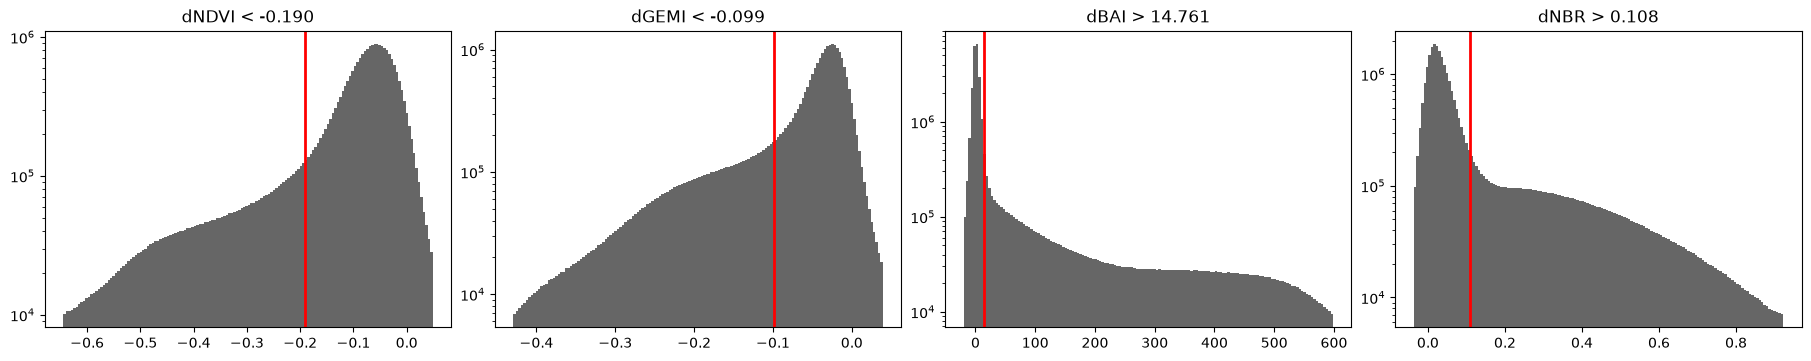

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.5), constrained_layout=True)
for a, (k, t) in zip(axs, thr.items()):
    v = idx[k][valid & np.isfinite(idx[k])]
    lo, hi = np.percentile(v, [0.5, 99.5])
    a.hist(v, bins=150, range=(lo, hi), color="#666")
    a.axvline(t["threshold"], color="red", lw=2)
    a.set_yscale("log"); a.set_title(f"{k} {t['op']} {t['threshold']:.3f}")
plt.show()

## 2. Clean-up tools
- **Majority filter** (course: 8 neighbours, MAJORITY): each pixel takes the value shared by ≥ 5 of its 8 neighbours. This removes "salt and pepper" speckle.
- **Remove small:** patches (and holes) smaller than 1 ha are dropped (or filled).
- `_label` gives each separate patch its own ID number, like colouring each island on a map differently.

In [4]:
def majority_filter(mask: np.ndarray) -> np.ndarray:
    k = np.ones((3, 3), int); k[1, 1] = 0
    n = ndimage.convolve(mask.astype(int), k, mode="nearest")   # burned neighbours per pixel
    return np.where(n >= 5, True, np.where(8 - n >= 5, False, mask))


def _label(mask):
    return ndimage.label(mask, structure=np.ones((3, 3)))


def remove_small(mask: np.ndarray, min_px: int) -> np.ndarray:
    lab, n = _label(mask)
    if n == 0:
        return mask
    keep = np.bincount(lab.ravel()) >= min_px
    keep[0] = False
    return keep[lab]


def clean(mask, valid, min_px):
    m = remove_small(majority_filter(mask & valid), min_px)
    return ~remove_small(~m, min_px) & valid      # also fill holes < min_px

## 3. One footprint per index, and the M separability check
**M = |mean burned − mean unburned| / (sd burned + sd unburned)**
M measures how well the two groups separate. **M > 1** = good separation. M < 1 = the index confuses the two.

In [5]:
def separability(values, burned, valid):
    ok = valid & np.isfinite(values)
    b, u = values[burned & ok], values[~burned & ok]
    if b.size < 2 or u.size < 2:
        return None
    return round(float(abs(b.mean() - u.mean()) / (b.std() + u.std())), 3)


seg, rows = {}, []
for k, t in thr.items():
    seg[k] = flag(idx[k], t["op"], t["threshold"]) & valid
    c = clean(seg[k], valid, min_px)
    rows.append({"index": k, "rule": f"{k} {t['op']} {t['threshold']}",
                 "area_km2": round(c.sum() * px_km2, 2), "M": separability(idx[k], c, valid)})
per_index = pd.DataFrame(rows)
per_index

,index,rule,area_km2,M
0,dNDVI,dNDVI < -0.19043,423.42,1.463
1,dGEMI,dGEMI < -0.09914,624.23,1.218
2,dBAI,dBAI > 14.76078,621.97,0.803
3,dNBR,dNBR > 0.10844,711.32,1.445


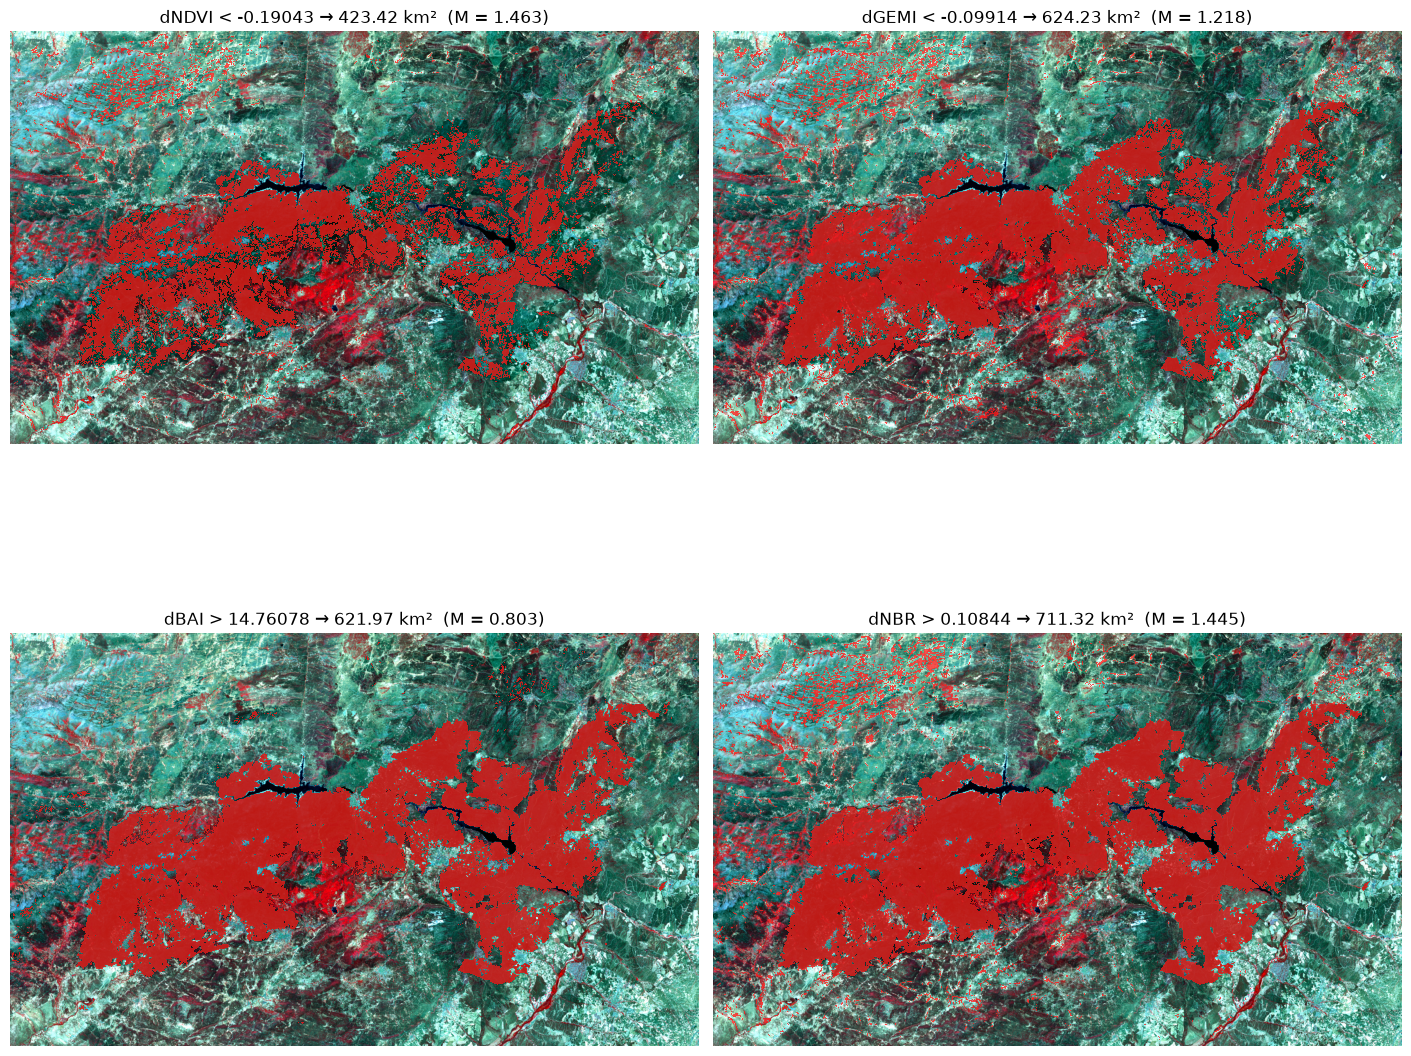

In [6]:
pre, _, _ = read_reflectance("pre")
post, _, _ = read_reflectance("post")
_, img, _, _ = false_color(pre, post)

fig, axs = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
for a, r in zip(axs.ravel(), rows):
    m = clean(seg[r["index"]], valid, min_px)
    a.imshow(img)
    a.imshow(np.ma.masked_where(~m, m), cmap=ListedColormap(["#ff1a1a"]), alpha=.75,
             interpolation="nearest")
    a.set_title(f"{r['rule']} → {r['area_km2']} km²  (M = {r['M']})"); a.set_axis_off()
fig.savefig(OUT / "step4_index_segmentations.png", dpi=110)
plt.show()

## 4. Voting: replacing the course's manual clean-up
After the Merge, the course deleted false polygons by hand. Here the indices "vote" instead:

- **Vegetation-loss indices** (ΔNDVI, ΔGEMI) also fire on a cereal field harvested in July.
- **Char indices** (dNBR, ΔBAI) respond to charcoal, not to harvest.

**Rules:**
- A pixel is a candidate if **≥ 2** of the 4 indices flag it.
- A patch is kept only if it contains **≥ 1 ha where ≥ 3 agree** *and* there is **strong char** (ΔBAI > 144.38).

A real fire patch always contains some truly charred ground. A harvested field doesn't.

In [7]:
def vote_and_clean(seg, strong_char, valid, min_px, pixel_votes, core_votes):
    votes = np.sum([m.astype(np.uint8) for m in seg.values()], axis=0)   # 0-4 per pixel
    cand = majority_filter((votes >= pixel_votes) & valid)
    lab, n = _label(cand)
    if n == 0:
        return cand, votes
    ids = np.arange(1, n + 1)
    core = ndimage.sum((votes >= core_votes) & strong_char & valid, lab, ids)  # core pixels per patch
    keep = np.zeros(n + 1, bool)
    keep[1:] = core >= min_px
    final = ~remove_small(~keep[lab], min_px)
    return final & valid, votes


strong = flag(idx["dBAI"], ">", STRONG_CHAR_DBAI) & valid
final, votes = vote_and_clean(seg, strong, valid, min_px, CFG["pixel_votes"], CFG["core_votes"])
area_km2 = round(final.sum() * px_km2, 3)
m_final = separability(idx["dNBR"], final, valid)
print(f"FINAL footprint: {area_km2} km²  ({area_km2 * 100:,.0f} ha)")
print(f"Validation: dNBR separability M = {m_final}")

FINAL footprint: 618.032 km²  (61,803 ha)
Validation: dNBR separability M = 1.513


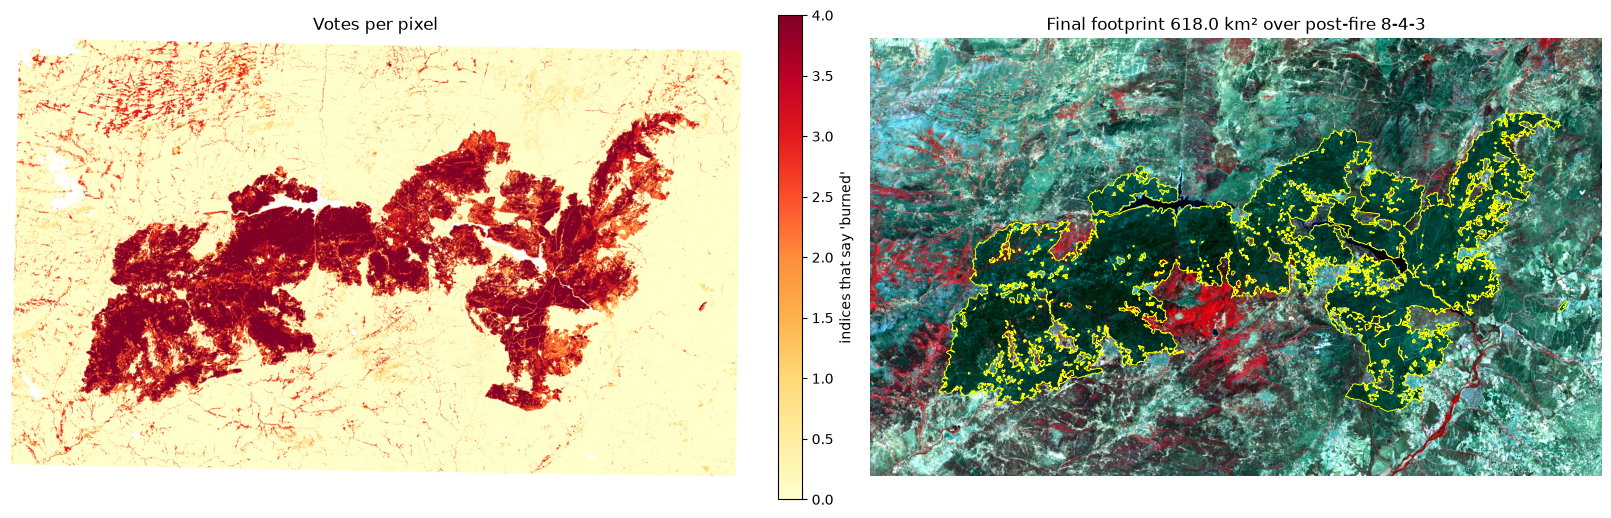

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
im = ax[0].imshow(np.where(valid, votes, np.nan), cmap="YlOrRd", vmin=0, vmax=4)
fig.colorbar(im, ax=ax[0], shrink=.7, label="indices that say 'burned'")
ax[0].set_title("Votes per pixel")
ax[1].imshow(img)
ax[1].contour(final, levels=[0.5], colors="yellow", linewidths=0.6)
ax[1].set_title(f"Final footprint {area_km2:.1f} km² over post-fire 8-4-3")
for a in ax:
    a.set_axis_off()
fig.savefig(OUT / "step4_footprint.png", dpi=150)
plt.show()

## 4b. Is the whole fire inside the study area?
If burned pixels reach the edge of the AOI, the fire probably continues outside it and the area is too small. This counts the footprint pixels right next to the AOI boundary. **Zero means the burn scar is fully inside.**

In [9]:
inside = aoi_mask(final.shape, transform, crs)
edge_band = ndimage.binary_dilation(~inside)            # pixels right next to the outside
on_edge = int((final & edge_band).sum())
print(f"Footprint pixels at the AOI edge: {on_edge}")
print("The burn scar is fully inside the AOI." if on_edge == 0 else "The burn scar reaches the edge: widen the bbox in common.py.")

Footprint pixels at the AOI edge: 0
The burn scar is fully inside the AOI.


## 5. Raster → polygons, and save
`features.shapes` traces the outline of every burned patch (Raster to Polygon). Then `dissolve` merges them into one feature (Dissolve). We save to:
- **GeoPackage** (`.gpkg`) for ArcGIS/QGIS: one file holding several layers.
- **GeoJSON** for the web map below.
- **KML** for Google Earth.

In [10]:
def vectorise(mask, transform, crs):
    geoms = [shape(g) for g, v in features.shapes(mask.astype("uint8"), mask=mask,
                                                   transform=transform) if v == 1]
    gdf = gpd.GeoDataFrame(geometry=geoms, crs=crs)
    if len(gdf):
        gdf = gdf.dissolve().reset_index(drop=True)
        gdf["area_ha"] = (gdf.area / 1e4).round(2)
        gdf["area_km2"] = (gdf.area / 1e6).round(4)
    return gdf


def outer_perimeter_km(gdf) -> float:
    if not len(gdf):
        return 0.0
    return round(sum(Polygon(p.exterior).length
                     for p in gdf.explode(index_parts=False).geometry) / 1e3, 2)


def write_kml(gdf, path, name):
    g = gdf.to_crs(4326)
    ring = lambda cs: " ".join(f"{x:.6f},{y:.6f},0" for x, y, *_ in cs)  # noqa: E731
    parts = []
    for geom in g.geometry:
        for p in ([geom] if isinstance(geom, Polygon) else list(geom.geoms)):
            inner = "".join(f"<innerBoundaryIs><LinearRing><coordinates>{ring(i.coords)}"
                            "</coordinates></LinearRing></innerBoundaryIs>" for i in p.interiors)
            parts.append(f"<Polygon><outerBoundaryIs><LinearRing><coordinates>"
                         f"{ring(p.exterior.coords)}</coordinates></LinearRing>"
                         f"</outerBoundaryIs>{inner}</Polygon>")
    path.write_text('<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/'
                    f'kml/2.2"><Document><name>{name}</name><Style id="b"><LineStyle><color>'
                    'ff0000ff</color><width>2</width></LineStyle><PolyStyle><color>5a0000ff'
                    '</color></PolyStyle></Style><Placemark><name>' + name + '</name><styleUrl>'
                    '#b</styleUrl><MultiGeometry>' + "".join(parts) +
                    '</MultiGeometry></Placemark></Document></kml>', encoding="utf-8")


gdf = vectorise(final, transform, crs)
gpkg = OUT / "burn_footprint.gpkg"
if gpkg.exists():
    gpkg.unlink()
gdf.to_file(gpkg, layer="footprint_dissolved", driver="GPKG")
aoi = aoi_polygon(crs)
gpd.GeoDataFrame({"area_km2": [round(aoi.area / 1e6, 2)]}, geometry=[aoi], crs=crs
                 ).to_file(gpkg, layer="aoi_extent", driver="GPKG")
for k, m in seg.items():
    vectorise(clean(m, valid, min_px), transform, crs).to_file(gpkg, layer=f"index_{k}", driver="GPKG")
gdf.to_crs(4326).to_file(OUT / "burn_footprint.geojson", driver="GeoJSON")
write_kml(gdf, OUT / "burn_footprint.kml", "Burn footprint (Sentinel-2)")
write_tif(OUT / "footprint_mask.tif", final.astype("uint8"), transform, crs, 255, ["burned"])
write_tif(OUT / "index_votes.tif", votes.astype("uint8"), transform, crs, 255, ["votes 0-4"])

per_km = outer_perimeter_km(gdf)
print(f"Outer perimeter: {per_km} km (pixel edges make it longer than an official perimeter)")
gdf

Outer perimeter: 1151.34 km (pixel edges make it longer than an official perimeter)


,geometry,area_ha,area_km2
0,"MULTIPOLYGON (((350520 4457490, 350510 4457490...",61803.17,618.0317


## 6. Interactive check
Switch to the **Satellite** layer (top-right icon) and zoom in. Look for footprint edges that cross farmland, because a harvested field *touching* the burn can still slip in.

In [11]:
import folium
m = aoi_map()
display_shape = gdf.simplify(15).to_crs(4326)   # lighter outline, for this map only
folium.GeoJson(display_shape.__geo_interface__, name="Burn footprint",
               style_function=lambda f: {"color": "yellow", "weight": 1.5, "fillOpacity": 0.25}
               ).add_to(m)
folium.LayerControl().add_to(m)
m.save(OUT / "footprint_map.html")
m

In [12]:
summary = {"thresholds": thr, "per_index": rows,
           "footprint": {"area_km2": area_km2, "area_ha": round(area_km2 * 100, 1),
                         "pct_of_aoi": round(100 * area_km2 / (aoi.area / 1e6), 1),
                         "outer_perimeter_km": per_km, "M_dNBR": m_final,
                         "pixels_on_aoi_edge": on_edge},
           "rules": {"pixel_votes": CFG["pixel_votes"], "core_votes": CFG["core_votes"],
                     "strong_char_dBAI": STRONG_CHAR_DBAI, "min_patch_ha": CFG["min_patch_ha"]}}
save_json(summary, "step4_footprint.json")

## What you learned
- A **threshold** turns a continuous index into yes/no. Learning it from the scene's own *unburned* pixels adapts it to this fire.
- **Robust statistics** (median, MAD) ignore a few extreme pixels.
- **Voting** across indices that fail in different ways cancels out their individual mistakes (harvest vs char).
- **Raster → vector** gives polygons you can measure, overlay and open in ArcGIS or Google Earth.

**Try it:** set `"pixel_votes": 3` in `common.py`, restart the kernel, rerun this notebook, and compare the area.

**Next:** `05_impact.ipynb`